# Fertilizer Recommendation System

Workflow: Dataset → Preprocessing → EDA → Model comparison → Evaluation → Prediction.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

%matplotlib inline
sns.set_style("whitegrid")

## 2. Load and explore the dataset

In [2]:
df = pd.read_csv("../data/raw/Fertilizer_Prediction.csv")
df.columns = [c.strip() for c in df.columns]
print(df.shape)
df.head()

(99, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26,52,38,Sandy,Maize,37,0,0,Urea
1,29,52,45,Loamy,Sugarcane,12,0,36,DAP
2,34,65,62,Black,Cotton,7,9,30,14-35-14
3,32,62,34,Red,Tobacco,22,0,20,28-28
4,28,54,46,Clayey,Paddy,35,0,0,Urea


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Temparature      99 non-null     int64
 1   Humidity         99 non-null     int64
 2   Moisture         99 non-null     int64
 3   Soil Type        99 non-null     str  
 4   Crop Type        99 non-null     str  
 5   Nitrogen         99 non-null     int64
 6   Potassium        99 non-null     int64
 7   Phosphorous      99 non-null     int64
 8   Fertilizer Name  99 non-null     str  
dtypes: int64(6), str(3)
memory usage: 7.1 KB


In [4]:
df.describe()

,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
count,99.000000,99.000000,99.000000,99.000000,99.000000,99.000000
mean,30.282828,59.151515,43.181818,18.909091,3.383838,18.606061
std,3.502304,5.840331,11.271568,11.599693,5.814667,13.476978
min,25.000000,50.000000,25.000000,4.000000,0.000000,0.000000
25%,28.000000,54.000000,34.000000,10.000000,0.000000,9.000000
50%,30.000000,60.000000,41.000000,13.000000,0.000000,19.000000
75%,33.000000,64.000000,50.500000,24.000000,7.500000,30.000000
max,38.000000,72.000000,65.000000,42.000000,19.000000,42.000000


## 3. Check and handle missing / duplicate values

In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
df = df.drop_duplicates()

Missing values per column:
Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis

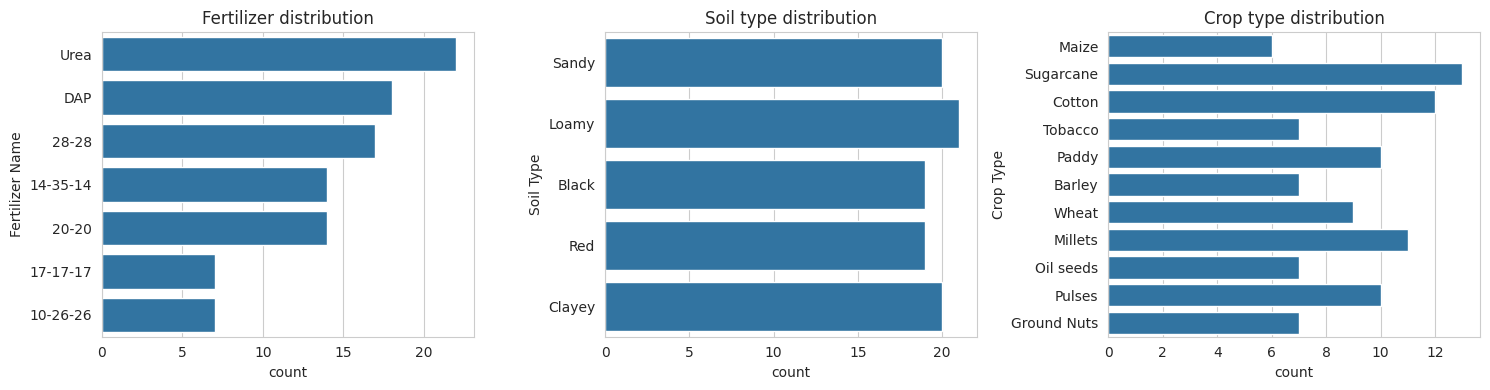

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(y="Fertilizer Name", data=df, order=df["Fertilizer Name"].value_counts().index, ax=axes[0])
axes[0].set_title("Fertilizer distribution")
sns.countplot(y="Soil Type", data=df, ax=axes[1])
axes[1].set_title("Soil type distribution")
sns.countplot(y="Crop Type", data=df, ax=axes[2])
axes[2].set_title("Crop type distribution")
plt.tight_layout()
plt.show()

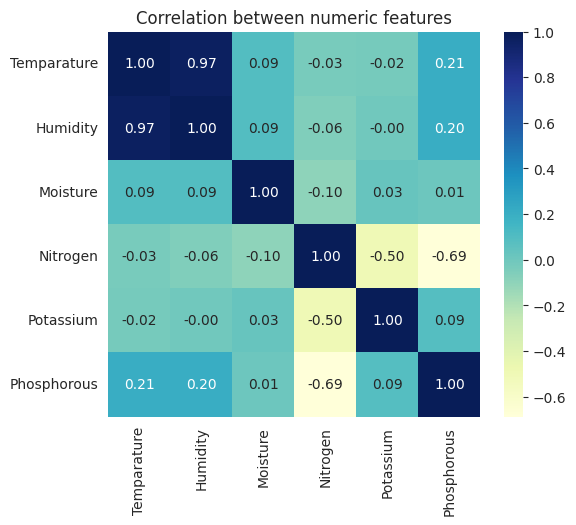

In [7]:
numeric_cols = ["Temparature", "Humidity", "Moisture", "Nitrogen", "Potassium", "Phosphorous"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Correlation between numeric features")
plt.show()

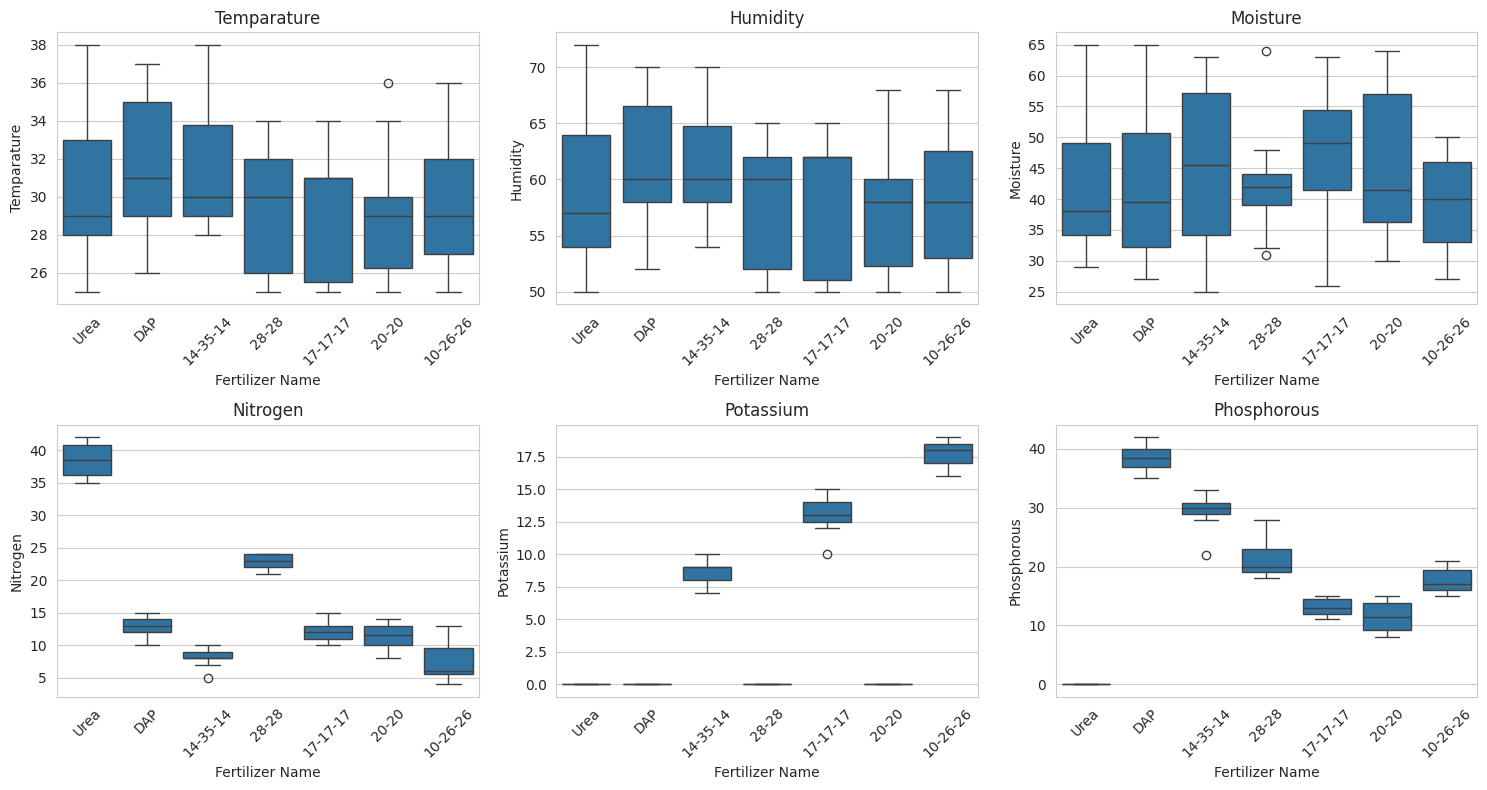

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(x="Fertilizer Name", y=col, data=df, ax=ax)
    ax.tick_params(axis='x', rotation=45)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Preprocessing: encode categorical features

In [9]:
soil_encoder = LabelEncoder()
crop_encoder = LabelEncoder()
label_encoder = LabelEncoder()

df["Soil Type_enc"] = soil_encoder.fit_transform(df["Soil Type"])
df["Crop Type_enc"] = crop_encoder.fit_transform(df["Crop Type"])
y = label_encoder.fit_transform(df["Fertilizer Name"])

feature_cols = numeric_cols + ["Soil Type_enc", "Crop Type_enc"]
X = df[feature_cols]
X.head()

,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous,Soil Type_enc,Crop Type_enc
0,26,52,38,37,0,0,4,3
1,29,52,45,12,0,36,2,8
2,34,65,62,7,9,30,0,1
3,32,62,34,22,0,20,3,9
4,28,54,46,35,0,0,1,6


## 6. Split into train/test sets

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(79, 8) (20, 8)


## 7. Train and compare models (Decision Tree, Random Forest, KNN)

In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=3),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results[name] = {
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, average="weighted", zero_division=0),
        "recall": recall_score(y_test, preds, average="weighted", zero_division=0),
        "f1": f1_score(y_test, preds, average="weighted", zero_division=0),
    }

results_df = pd.DataFrame(results).T
results_df

,accuracy,precision,recall,f1
Decision Tree,0.95,0.975,0.95,0.953333
Random Forest,1.00,1.000,1.00,1.000000
KNN,0.95,0.975,0.95,0.953333


## 8. Evaluate the best model: confusion matrix + classification report

Best model: Random Forest


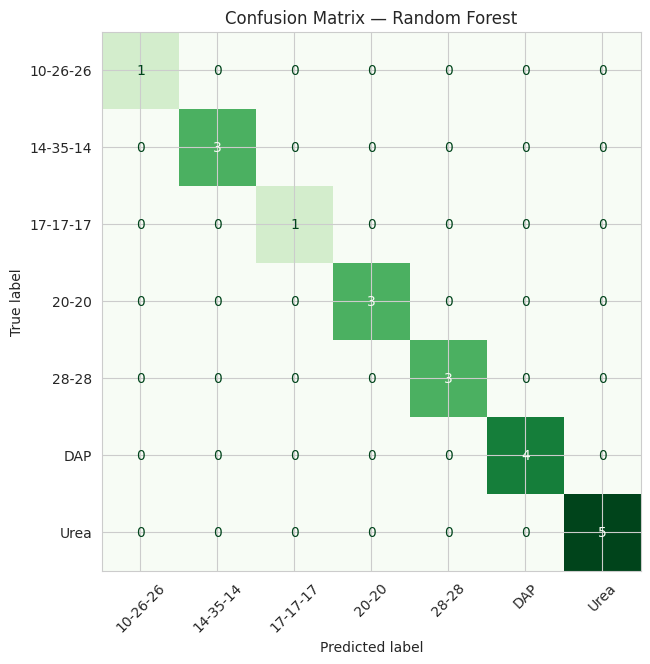

              precision    recall  f1-score   support

    10-26-26       1.00      1.00      1.00         1
    14-35-14       1.00      1.00      1.00         3
    17-17-17       1.00      1.00      1.00         1
       20-20       1.00      1.00      1.00         3
       28-28       1.00      1.00      1.00         3
         DAP       1.00      1.00      1.00         4
        Urea       1.00      1.00      1.00         5

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



In [12]:
best_name = results_df["f1"].idxmax()
best_model = models[best_name]
print(f"Best model: {best_name}")

preds = best_model.predict(X_test)
cm = confusion_matrix(y_test, preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, xticks_rotation=45, cmap="Greens", colorbar=False)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

print(classification_report(y_test, preds, target_names=label_encoder.classes_, zero_division=0))

## 9. Predict a fertilizer for a new sample

In [13]:
sample = pd.DataFrame([{
    "Temparature": 26,
    "Humidity": 52,
    "Moisture": 38,
    "Nitrogen": 37,
    "Potassium": 0,
    "Phosphorous": 0,
    "Soil Type_enc": soil_encoder.transform(["Sandy"])[0],
    "Crop Type_enc": crop_encoder.transform(["Maize"])[0],
}])[feature_cols]

pred = best_model.predict(sample)[0]
print("Recommended fertilizer:", label_encoder.inverse_transform([pred])[0])

Recommended fertilizer: Urea


## 10. Save the model and encoders

See `train_model.py` for the version used by the Flask app (`app.py`) — it performs the same steps and saves `models/fertilizer_model.pkl` and `models/encoders.pkl`.